## 1. Setup

In [130]:

import sys
from pathlib import Path

try:
    from google.colab import drive
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

USE_DRIVE = IN_COLAB

#Set dataset path
DRIVE_DATA_ROOT = "/content/drive/MyDrive/CP467_Traffic_Signs/data/raw"

print("Running in Colab:", IN_COLAB)
print("Python:", sys.version)

Running in Colab: True
Python: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]


In [131]:

import os
import subprocess

#Mount Google Drive
if USE_DRIVE and IN_COLAB:
    drive.mount("/content/drive")

#Find project folder
PROJECT_ROOT = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if (p / "src" / "config.py").is_file() and (p / "requirements.txt").is_file()),
    None,
)

#Clone repo if not found
if PROJECT_ROOT is None and IN_COLAB:
    PROJECT_ROOT = Path("/content/CP467GroupProject")

    if not PROJECT_ROOT.exists():
        subprocess.run(
            ["git", "clone", "--depth", "1",
             "https://github.com/Davy-Chu/CP467GroupProject.git", str(PROJECT_ROOT)],
            check=True,
        )

if PROJECT_ROOT is None or not (PROJECT_ROOT / "src" / "config.py").is_file():
    raise RuntimeError("Project folder not found.")

#Set working directory
os.chdir(PROJECT_ROOT)

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print("Project root:", PROJECT_ROOT)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Project root: /content/CP467GroupProject


In [132]:

#Install dependencies if needed
INSTALL_DEPENDENCIES = False

if INSTALL_DEPENDENCIES:
    subprocess.run(
        [sys.executable, "-m", "pip", "install", "-r", str(PROJECT_ROOT / "requirements.txt")],
        check=True,
    )

#Import libraries
import cv2
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import skimage
import sklearn
import torch
import torchvision
import seaborn

#Check library versions
for library in (cv2, np, pd, matplotlib, skimage, sklearn, torch, torchvision, seaborn):
    print(f"{library.__name__}: {library.__version__}")

cv2: 5.0.0
numpy: 2.4.6
pandas: 2.2.3
matplotlib: 3.10.0
skimage: 0.25.2
sklearn: 1.6.1
torch: 2.14.1+cpu
torchvision: 0.29.1+cpu
seaborn: 0.13.2


In [133]:

#Import project settings
from src.config import (
    NUM_CLASSES, IMAGE_SIZE, RANDOM_SEED, REPO_DATA_ROOT,
    RESULTS_DIR, MODELS_DIR, CONDITIONS, DEGRADATION_PARAMS,
    get_data_root, seed_everything,
)

#Import dataset functions
from src.data_utils import (
    validate_dataset, load_metadata, load_image,
    make_train_validation_split, split_fingerprint,
)

#Import image processing functions
from src.degradations import (
    apply_condition, reduce_brightness, add_noise, apply_motion_blur,
    equalize_histogram, gaussian_filter,
)

#Set seed and dataset path
seed_everything()
DATA_ROOT = get_data_root(USE_DRIVE, DRIVE_DATA_ROOT)

print("Selected data root:", DATA_ROOT)
print("Repository fallback:", REPO_DATA_ROOT)
print("Shared conditions:", DEGRADATION_PARAMS)

Selected data root: /content/drive/.shortcut-targets-by-id/1FsBmRpQD63fnmP2odgoMoYPisfonn987/CP467_Traffic_Signs/data/raw
Repository fallback: /content/CP467GroupProject/Dataset/raw
Shared conditions: {'brightness': {'factor': 0.5}, 'noise': {'std': 0.05}, 'motion_blur': {'kernel_size': 9}}


## 2. Load Dataset

In [153]:

#Load full dataset
training_metadata, test_metadata = validate_dataset(
    DATA_ROOT,
    check_images="sample",
)

#Use same training and validation split as CNN
train_metadata, validation_metadata = make_train_validation_split(
    training_metadata
)

SPLIT_ID = split_fingerprint(
    train_metadata,
    validation_metadata,
)

#Display dataset information
print("Training:", len(train_metadata))
print("Validation:", len(validation_metadata))
print("Testing:", len(test_metadata))
print("Classes:", training_metadata["ClassId"].nunique())
print("Split ID:", SPLIT_ID)

=== EXPECTED DATASET SPLIT ===
Training images: 31367
Validation images: 7842
Testing images: 12630
Classes: 43
Random seed: 42
Split ID: 2947e8e993860c74


In [135]:

#Train HOG + SVM with available images
x_train, y_train = extract_hog_dataset(train_metadata)
x_val, y_val = extract_hog_dataset(validation_metadata)

print("Training shape:", x_train.shape)
print("Validation shape:", x_val.shape)

#Train SVM and find best C
best_svm, svm_results = train_svm(
    x_train,
    y_train,
    x_val,
    y_val,
)

#Evaluate model on validation data
svm_metrics, svm_predictions = evaluate_svm(
    best_svm,
    x_val,
    y_val,
)

display(svm_results)

Training shape: (4608, 324)
Validation shape: (1152, 324)
C=0.1 | Validation accuracy=0.9592 | Training time=1.30s
C=1 | Validation accuracy=0.9931 | Training time=0.82s
C=10 | Validation accuracy=0.9974 | Training time=0.81s

Best C: 10
Best validation accuracy: 0.9974
Accuracy: 0.9974
Macro F1-score: 0.9927
Average inference: 0.3109 ms/image


,C,validation_accuracy,training_time_seconds
0,0.1,0.959201,1.298517
1,1.0,0.993056,0.818983
2,10.0,0.997396,0.807123


## 3. Preprocessing

In [136]:

#Preprocess image for HOG
def preprocess_for_hog(image, preprocessing="none"):
    if image.shape != (32, 32, 3):
        raise ValueError("Expected a 32x32 RGB image.")

    if image.dtype != np.uint8:
        raise TypeError("Expected a uint8 RGB image.")

    #Apply optional preprocessing
    if preprocessing == "equalize":
        image = equalize_histogram(image)
    elif preprocessing == "gaussian":
        image = gaussian_filter(image, kernel_size=3, sigma=1.0)
    elif preprocessing != "none":
        raise ValueError(f"Unknown preprocessing: {preprocessing}")

    #Convert to grayscale and normalize
    grayscale = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)
    grayscale = grayscale.astype(np.float32) / 255.0

    return grayscale

All preprocessing tests passed!
Output shape: (32, 32)
Pixel range: 0.0 1.0


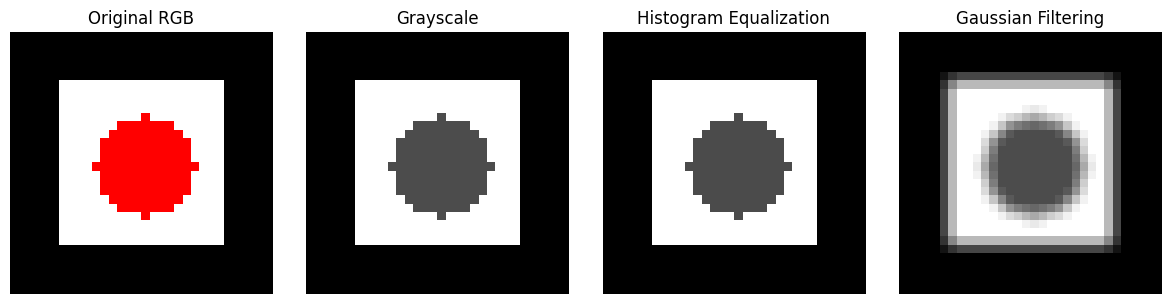

In [137]:

#Create test image
test_image = np.zeros((32, 32, 3), dtype=np.uint8)

cv2.rectangle(test_image, (6, 6), (25, 25), (255, 255, 255), -1)
cv2.circle(test_image, (16, 16), 6, (255, 0, 0), -1)

#Test grayscale conversion
processed_image = preprocess_for_hog(test_image)

assert processed_image.shape == (32, 32)
assert processed_image.dtype == np.float32
assert 0.0 <= processed_image.min()
assert processed_image.max() <= 1.0

#Test other preprocessing methods
equalized_image = preprocess_for_hog(test_image, "equalize")
filtered_image = preprocess_for_hog(test_image, "gaussian")

assert equalized_image.shape == (32, 32)
assert filtered_image.shape == (32, 32)

print("All preprocessing tests passed!")
print("Output shape:", processed_image.shape)
print("Pixel range:", processed_image.min(), processed_image.max())

#Display preprocessing results
fig, axes = plt.subplots(1, 4, figsize=(12, 3))

images = [
    test_image,
    processed_image,
    equalized_image,
    filtered_image,
]

titles = [
    "Original RGB",
    "Grayscale",
    "Histogram Equalization",
    "Gaussian Filtering",
]

for axis, image, title in zip(axes, images, titles):
    axis.imshow(image, cmap="gray" if image.ndim == 2 else None)
    axis.set_title(title)
    axis.axis("off")

plt.tight_layout()
plt.show()

## 4. HOG Feature Extraction

In [138]:

from skimage.feature import hog

#Set HOG parameters
HOG_PARAMS = {
    "orientations": 9,
    "pixels_per_cell": (8, 8),
    "cells_per_block": (2, 2),
    "block_norm": "L2-Hys",
}

#Extract HOG features from image
def extract_hog_features(image, preprocessing="none"):
    grayscale = preprocess_for_hog(image, preprocessing)

    features = hog(
        grayscale,
        **HOG_PARAMS,
        feature_vector=True,
    )

    return features.astype(np.float32)


#Extract features and labels from dataset
def extract_hog_dataset(metadata, preprocessing="none"):
    features = []
    labels = []

    for row in metadata.itertuples(index=False):
        image = load_image(DATA_ROOT, row.Path)
        hog_features = extract_hog_features(image, preprocessing)

        features.append(hog_features)
        labels.append(row.ClassId)

    return np.asarray(features), np.asarray(labels)

HOG feature extraction passed!
Feature vector shape: (324,)
Feature count: 324


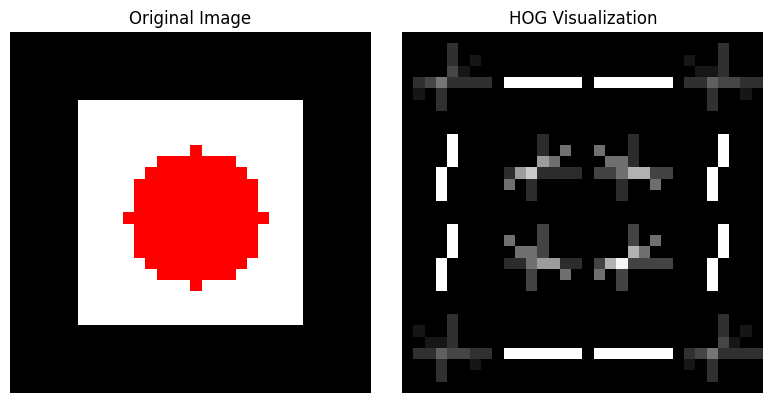

In [139]:

#Test HOG feature extraction
test_features = extract_hog_features(test_image)

assert test_features.shape == (324,)
assert np.all(np.isfinite(test_features))

print("HOG feature extraction passed!")
print("Feature vector shape:", test_features.shape)
print("Feature count:", len(test_features))

#Generate HOG visualization
grayscale = preprocess_for_hog(test_image)

_, hog_visualization = hog(
    grayscale,
    **HOG_PARAMS,
    visualize=True,
)

#Display original and HOG images
fig, axes = plt.subplots(1, 2, figsize=(8, 4))

axes[0].imshow(test_image)
axes[0].set_title("Original Image")

axes[1].imshow(hog_visualization, cmap="gray")
axes[1].set_title("HOG Visualization")

for axis in axes:
    axis.axis("off")

plt.tight_layout()
plt.show()

## 5. Train SVM

In [140]:
import time

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

#Train SVM and find best C
def train_svm(x_train, y_train, x_val, y_val, c_values=(0.1, 1, 10)):
    best_model = None
    best_accuracy = -1
    best_c = None
    results = []

    for c in c_values:
        #Create SVM model
        model = make_pipeline(
            StandardScaler(),
            SVC(kernel="rbf", C=c, gamma="scale"),
        )

        #Train model and measure time
        start_time = time.perf_counter()
        model.fit(x_train, y_train)
        training_time = time.perf_counter() - start_time

        #Check validation accuracy
        predictions = model.predict(x_val)
        validation_accuracy = accuracy_score(y_val, predictions)

        results.append({
            "C": c,
            "validation_accuracy": validation_accuracy,
            "training_time_seconds": training_time,
        })

        print(
            f"C={c} | "
            f"Validation accuracy={validation_accuracy:.4f} | "
            f"Training time={training_time:.2f}s"
        )

        #Keep best model
        if validation_accuracy > best_accuracy:
            best_accuracy = validation_accuracy
            best_model = model
            best_c = c

    print(f"\nBest C: {best_c}")
    print(f"Best validation accuracy: {best_accuracy:.4f}")

    return best_model, pd.DataFrame(results)

In [141]:
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split

#Create sample data to test SVM
x_sample, y_sample = make_classification(
    n_samples=200,
    n_features=324,
    n_informative=20,
    n_redundant=10,
    n_classes=4,
    random_state=42,
)

#Split sample data
x_sample_train, x_sample_val, y_sample_train, y_sample_val = train_test_split(
    x_sample,
    y_sample,
    test_size=0.2,
    random_state=42,
    stratify=y_sample,
)

#Train SVM on sample data
test_model, test_results = train_svm(
    x_sample_train,
    y_sample_train,
    x_sample_val,
    y_sample_val,
)

#Check training results
assert test_model is not None
assert len(test_results) == 3
assert test_results["validation_accuracy"].between(0, 1).all()

print("\nSVM training test passed!")
print(test_results)

C=0.1 | Validation accuracy=0.2500 | Training time=0.01s
C=1 | Validation accuracy=0.4500 | Training time=0.01s
C=10 | Validation accuracy=0.4250 | Training time=0.01s

Best C: 1
Best validation accuracy: 0.4500

SVM training test passed!
      C  validation_accuracy  training_time_seconds
0   0.1                0.250               0.007245
1   1.0                0.450               0.008573
2  10.0                0.425               0.008684


## 6. Validation

In [142]:
import time

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

#Evaluate SVM model
def evaluate_svm(model, x_test, y_test):
    start_time = time.perf_counter()
    predictions = model.predict(x_test)
    inference_time = time.perf_counter() - start_time

    #Calculate accuracy and F1
    accuracy = accuracy_score(y_test, predictions)
    macro_f1 = f1_score(
        y_test,
        predictions,
        average="macro",
        zero_division=0,
    )

    average_inference_time = inference_time / len(x_test)

    metrics = {
        "accuracy": accuracy,
        "macro_f1": macro_f1,
        "total_inference_seconds": inference_time,
        "average_inference_seconds": average_inference_time,
    }

    print(f"Accuracy: {accuracy:.4f}")
    print(f"Macro F1-score: {macro_f1:.4f}")
    print(f"Average inference: {average_inference_time * 1000:.4f} ms/image")

    return metrics, predictions


#Plot confusion matrix
def plot_confusion_matrix(y_true, predictions, title):
    matrix = confusion_matrix(y_true, predictions)

    fig, ax = plt.subplots(figsize=(10, 8))

    matrix_display = ConfusionMatrixDisplay(confusion_matrix=matrix)
    matrix_display.plot(ax=ax, cmap="Blues", colorbar=True)

    ax.set_title(title)
    plt.tight_layout()
    plt.show()


#Show correct and incorrect predictions
def show_prediction_examples(y_true, predictions, max_examples=5):
    correct_indices = np.where(y_true == predictions)[0]
    incorrect_indices = np.where(y_true != predictions)[0]

    print("Correct predictions:")
    for index in correct_indices[:max_examples]:
        print(f"  Index {index}: True={y_true[index]}, Predicted={predictions[index]}")

    print("\nIncorrect predictions:")
    for index in incorrect_indices[:max_examples]:
        print(f"  Index {index}: True={y_true[index]}, Predicted={predictions[index]}")

Accuracy: 0.4500
Macro F1-score: 0.4183
Average inference: 0.0923 ms/image

SVM evaluation tests passed!


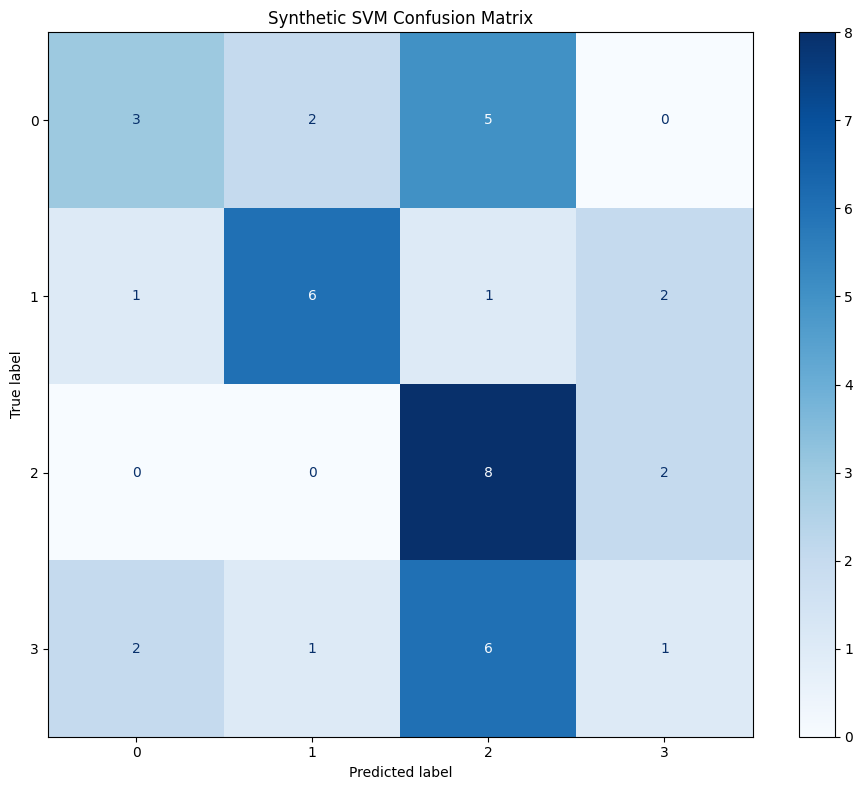

Correct predictions:
  Index 1: True=2, Predicted=2
  Index 3: True=1, Predicted=1
  Index 5: True=3, Predicted=3
  Index 8: True=2, Predicted=2
  Index 11: True=2, Predicted=2

Incorrect predictions:
  Index 0: True=0, Predicted=1
  Index 2: True=0, Predicted=2
  Index 4: True=3, Predicted=2
  Index 6: True=3, Predicted=1
  Index 7: True=2, Predicted=3


In [143]:
#Test SVM evaluation
test_metrics, test_predictions = evaluate_svm(
    test_model,
    x_sample_val,
    y_sample_val,
)

#Check evaluation results
assert 0 <= test_metrics["accuracy"] <= 1
assert 0 <= test_metrics["macro_f1"] <= 1
assert len(test_predictions) == len(y_sample_val)

print("\nSVM evaluation tests passed!")

#Display confusion matrix
plot_confusion_matrix(
    y_sample_val,
    test_predictions,
    "Synthetic SVM Confusion Matrix",
)

#Show prediction examples
show_prediction_examples(
    y_sample_val,
    test_predictions,
)

## 7. Clean Test Evaluation

In [144]:
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

#Extract HOG features for different conditions
def extract_condition_features(metadata, condition="clean", preprocessing="none"):
    features = []
    labels = []

    for row in metadata.itertuples(index=False):
        image = load_image(DATA_ROOT, row.Path)
        image = apply_condition(image, condition, image_id=row.Path)

        features.append(extract_hog_features(image, preprocessing))
        labels.append(row.ClassId)

    return np.asarray(features, dtype=np.float32), np.asarray(labels)


#Evaluate model under different conditions
def evaluate_condition(model, metadata, condition="clean", preprocessing="none"):
    x, y = extract_condition_features(metadata, condition, preprocessing)
    predictions = model.predict(x)

    class_ids = sorted(metadata["ClassId"].unique())

    return {
        "condition": condition,
        "preprocessing": preprocessing,
        "accuracy": accuracy_score(y, predictions),
        "macro_f1": f1_score(
            y,
            predictions,
            labels=class_ids,
            average="macro",
            zero_division=0,
        ),
        "predictions": predictions,
        "labels": y,
    }


#Evaluate clean validation images
clean_results = evaluate_condition(
    best_svm,
    validation_metadata,
    condition="clean",
)

print("Clean accuracy:", clean_results["accuracy"])
print("Clean macro F1:", clean_results["macro_f1"])

Clean accuracy: 0.9973958333333334
Clean macro F1: 0.992749355679526


## 8. Degraded Test Evaluation

In [145]:
#Test SVM on different image conditions
def run_degradation_experiments(model, metadata):
    experiments = [
        ("clean", "none"),
        ("brightness", "none"),
        ("noise", "none"),
        ("motion_blur", "none"),
        ("brightness", "equalize"),
        ("noise", "gaussian"),
    ]

    results = []

    for condition, preprocessing in experiments:
        #Evaluate each condition
        result = evaluate_condition(
            model,
            metadata,
            condition=condition,
            preprocessing=preprocessing,
        )

        class_ids = sorted(metadata["ClassId"].unique())

        macro_f1 = f1_score(
            result["labels"],
            result["predictions"],
            labels=class_ids,
            average="macro",
            zero_division=0,
        )

        results.append({
            "condition": condition,
            "preprocessing": preprocessing,
            "accuracy": result["accuracy"],
            "macro_f1": macro_f1,
        })

        print(
            f"{condition} | {preprocessing} | "
            f"Accuracy: {result['accuracy']:.4f} | "
            f"Macro F1: {macro_f1:.4f}"
        )

    #Calculate accuracy drop from clean images
    results_df = pd.DataFrame(results)

    clean_accuracy = results_df.loc[
        results_df["condition"] == "clean",
        "accuracy",
    ].iloc[0]

    results_df["accuracy_drop"] = (
        clean_accuracy - results_df["accuracy"]
    )

    return results_df


#Run experiments on validation images
degradation_results = run_degradation_experiments(
    best_svm,
    validation_metadata,
)

print("\n=== FOUR-CLASS DEGRADATION RESULTS ===")
display(degradation_results)

clean | none | Accuracy: 0.9974 | Macro F1: 0.9927
brightness | none | Accuracy: 0.9965 | Macro F1: 0.9864
noise | none | Accuracy: 0.7370 | Macro F1: 0.7540
motion_blur | none | Accuracy: 0.6493 | Macro F1: 0.4645
brightness | equalize | Accuracy: 0.9870 | Macro F1: 0.9639
noise | gaussian | Accuracy: 0.9175 | Macro F1: 0.8990

=== FOUR-CLASS DEGRADATION RESULTS ===


,condition,preprocessing,accuracy,macro_f1,accuracy_drop
0,clean,none,0.997396,0.992749,0.000000
1,brightness,none,0.996528,0.986379,0.000868
2,noise,none,0.736979,0.753969,0.260417
3,motion_blur,none,0.649306,0.464523,0.348090
4,brightness,equalize,0.986979,0.963944,0.010417
5,noise,gaussian,0.917535,0.899035,0.079861


## 9. Timing

In [146]:
import time

#Measure inference time
def measure_inference_time(model, metadata, condition="clean", max_images=100):
    sample = metadata.head(max_images)

    if sample.empty:
        raise ValueError("No images provided for timing.")

    times = []

    for row in sample.itertuples(index=False):
        start = time.perf_counter()

        #Load image and apply condition
        image = load_image(DATA_ROOT, row.Path)
        image = apply_condition(image, condition, image_id=row.Path)

        #Extract features and predict
        features = extract_hog_features(image).reshape(1, -1)
        model.predict(features)

        elapsed = time.perf_counter() - start
        times.append(elapsed)

    return {
        "num_images": len(times),
        "average_ms": np.mean(times) * 1000,
        "median_ms": np.median(times) * 1000,
        "total_seconds": np.sum(times),
    }


#Test inference time on validation images
timing_results = measure_inference_time(
    best_svm,
    validation_metadata,
    max_images=20,
)

print("Images tested:", timing_results["num_images"])
print(f"Average end-to-end inference: {timing_results['average_ms']:.4f} ms/image")
print(f"Median end-to-end inference: {timing_results['median_ms']:.4f} ms/image")

Images tested: 20
Average end-to-end inference: 8.3272 ms/image
Median end-to-end inference: 8.0993 ms/image


## 10. Confusion Matrix

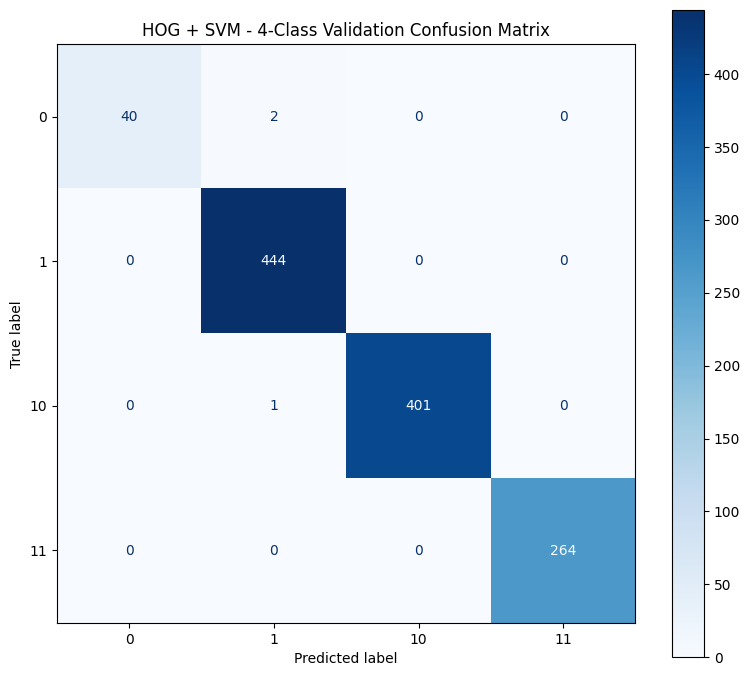

Confusion matrix saved: /content/CP467GroupProject/results/figures/hog_svm_validation_confusion_matrix.png


In [147]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

#Get class labels
class_ids = sorted(validation_metadata["ClassId"].unique())

#Create confusion matrix
matrix = confusion_matrix(
    y_val,
    svm_predictions,
    labels=class_ids,
)

#Plot confusion matrix
fig, ax = plt.subplots(figsize=(8, 7))

ConfusionMatrixDisplay(
    confusion_matrix=matrix,
    display_labels=class_ids,
).plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
)

ax.set_title("HOG + SVM - 4-Class Validation Confusion Matrix")
plt.tight_layout()

#Save confusion matrix
save_path = RESULTS_DIR / "figures" / "hog_svm_validation_confusion_matrix.png"
save_path.parent.mkdir(parents=True, exist_ok=True)

fig.savefig(save_path, dpi=200, bbox_inches="tight")

plt.show()
plt.close(fig)

print("Confusion matrix saved:", save_path)

## 11. Save Results

In [148]:
import json
import joblib

#Save SVM model and results
def save_svm_results(model, clean_results, degradation_results, timing_results):
    results_dir = RESULTS_DIR / "metrics"
    figures_dir = RESULTS_DIR / "figures"

    results_dir.mkdir(parents=True, exist_ok=True)
    figures_dir.mkdir(parents=True, exist_ok=True)
    MODELS_DIR.mkdir(parents=True, exist_ok=True)

    #Save degradation results
    results_frame = degradation_results.copy()
    results_frame.insert(0, "model", "HOG + SVM")

    results_frame.to_csv(
        results_dir / "hog_svm_metrics.csv",
        index=False,
    )

    #Save model configuration
    configuration = {
        "model": "HOG + SVM",
        "random_seed": RANDOM_SEED,
        "image_size": list(IMAGE_SIZE),
        "num_classes": len(np.unique(y_train)),
        "split_id": SPLIT_ID,
        "hog_parameters": HOG_PARAMS,
        "degradation_parameters": DEGRADATION_PARAMS,
        "best_svm_parameters": model.get_params(),
        "timing": timing_results,
        "evaluation_split": "validation",
    }

    with open(results_dir / "hog_svm_config.json", "w") as file:
        json.dump(configuration, file, indent=2, default=str)

    #Save trained SVM
    joblib.dump(model, MODELS_DIR / "hog_svm.pkl")

    print("Saved metrics, configuration, and trained model.")

    return results_frame


#Save results from 4-class validation
final_results = save_svm_results(
    best_svm,
    clean_results,
    degradation_results,
    timing_results,
)

display(final_results)

Saved metrics, configuration, and trained model.


,model,condition,preprocessing,accuracy,macro_f1,accuracy_drop
0,HOG + SVM,clean,none,0.997396,0.992749,0.000000
1,HOG + SVM,brightness,none,0.996528,0.986379,0.000868
2,HOG + SVM,noise,none,0.736979,0.753969,0.260417
3,HOG + SVM,motion_blur,none,0.649306,0.464523,0.348090
4,HOG + SVM,brightness,equalize,0.986979,0.963944,0.010417
5,HOG + SVM,noise,gaussian,0.917535,0.899035,0.079861


In [149]:
#Display HOG + SVM results
print("=== HOG + SVM RESULTS ===")
print(f"Training images: {len(train_metadata)}")
print(f"Validation images: {len(validation_metadata)}")
print(f"Classes: {len(np.unique(y_train))}")
print(f"Accuracy: {svm_metrics['accuracy']:.4f}")
print(f"Macro F1: {svm_metrics['macro_f1']:.4f}")
print(f"Model-only inference: {svm_metrics['average_inference_seconds'] * 1000:.4f} ms/image")

display(svm_results)

=== HOG + SVM RESULTS ===
Training images: 4608
Validation images: 1152
Classes: 4
Accuracy: 0.9974
Macro F1: 0.9927
Model-only inference: 0.3109 ms/image


,C,validation_accuracy,training_time_seconds
0,0.1,0.959201,1.298517
1,1.0,0.993056,0.818983
2,10.0,0.997396,0.807123


In [150]:
print("Model:", (MODELS_DIR / "hog_svm.pkl").exists())
print("Metrics:", (RESULTS_DIR / "metrics" / "hog_svm_metrics.csv").exists())
print("Config:", (RESULTS_DIR / "metrics" / "hog_svm_config.json").exists())
print("Confusion matrix:", save_path.exists())

Model: True
Metrics: True
Config: True
Confusion matrix: True


In [151]:

import shutil
from pathlib import Path
from google.colab import files

#Create export folders
export_dir = Path("/content/hog_svm_export")

if export_dir.exists():
    shutil.rmtree(export_dir)

(export_dir / "models").mkdir(parents=True)
(export_dir / "results" / "metrics").mkdir(parents=True)
(export_dir / "results" / "figures").mkdir(parents=True)

#Copy trained model
shutil.copy2(
    MODELS_DIR / "hog_svm.pkl",
    export_dir / "models" / "hog_svm.pkl",
)

#Copy metrics and configuration
for filename in ["hog_svm_metrics.csv", "hog_svm_config.json"]:
    shutil.copy2(
        RESULTS_DIR / "metrics" / filename,
        export_dir / "results" / "metrics" / filename,
    )

#Copy confusion matrix
shutil.copy2(
    save_path,
    export_dir / "results" / "figures" / save_path.name,
)

#Save hyperparameter results
svm_results.to_csv(
    export_dir / "results" / "metrics" / "hog_svm_hyperparameters.csv",
    index=False,
)

#Create ZIP file
shutil.make_archive(
    "/content/hog_svm_export",
    "zip",
    export_dir,
)

#Show files
print("=== FILES READY ===")

for path in export_dir.rglob("*"):
    if path.is_file():
        print(path.relative_to(export_dir))

#Download ZIP
files.download("/content/hog_svm_export.zip")


=== FILES READY ===
models/hog_svm.pkl
results/metrics/hog_svm_config.json
results/metrics/hog_svm_metrics.csv
results/metrics/hog_svm_hyperparameters.csv
results/figures/hog_svm_validation_confusion_matrix.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>